# Модель оценки стоимости вторичной недвижимости: эконометрика и OLS

Зачем бизнесу этот проект:
Сервисам недвижимости и банкам нужен прозрачный алгоритм быстрой оценки квартир для выдачи ипотеки и трейд-ина
В отличие от черного ящика бустинга эконометрика показывает точную физику рынка:
Сколько стоит чистый квадратный метр в каждом районе
Какой реальный штраф дает первый этаж или долгая дорога до метро
Как ремонт меняет ценник квартиры при одинаковой площади


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from multicollinearity import vif

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)


Файл локально создан без использования интернета!


## 1. Загрузка данных и первичный осмотр
Смотрим на сырой датасет объявлений: 12 500 строк и 13 колонок
В данных есть пропуски в площади кухни (типично для студий со свободной планировкой)


In [11]:
df = pd.read_csv("real_estate_dataset.csv")
df
# присутствуют пропущенные значения в kitchen area , типы норм

,flat_id,district,rooms,total_area,living_area,kitchen_area,floor,floors_total,building_type,renovation,minutes_to_metro,has_parking,price
0,10001,Северный,3,80.0,43.8,12.2,19,25,панель,евроремонт,7,0,18730000
1,10002,Пригород,1,36.6,21.9,5.1,20,22,кирпич,евроремонт,17,0,4700000
2,10003,Южный,1,31.7,20.3,6.5,19,22,Панель,без ремонта,32,0,3720000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12497,22498,Западный,4,106.0,62.4,18.5,11,22,панель,дизайнерский,3,1,31440000
12498,22499,Южный,2,50.1,31.8,6.7,10,16,монолит,без ремонта,25,1,7640000
12499,22500,Восточный,4,110.6,63.5,18.3,3,25,панель,евроремонт,6,1,25220000


## 2. Чистка категорий и генерация этажей
Убираем разнобой в названиях типов домов: приводим к нижнему регистру и отсекаем пробелы
Создаем два бинарных флага крайних этажей (первый и последний), так как рынок почти всегда дисконтирует такие квартиры


In [44]:
df["building_type"] = df["building_type"].str.strip().str.lower()
df["building_type"].unique()
df = df.assign(
    is_first_floor=lambda x: x["floor"] == 1,
    is_last_floor=lambda x: x["floor"] == x["floors_total"],
).astype({"is_first_floor": float, "is_last_floor": float})
df

,flat_id,district,rooms,total_area,living_area,kitchen_area,floor,floors_total,building_type,renovation,minutes_to_metro,has_parking,price,is_first_floor,is_last_floor
0,10001,Северный,3,80.00,43.80,12.20,19,25,панель,евроремонт,7,0,18730000,0.00,0.00
1,10002,Пригород,1,36.60,21.90,5.10,20,22,кирпич,евроремонт,17,0,4700000,0.00,0.00
2,10003,Южный,1,31.70,20.30,6.50,19,22,панель,без ремонта,32,0,3720000,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12497,22498,Западный,4,106.00,62.40,18.50,11,22,панель,дизайнерский,3,1,31440000,0.00,0.00
12498,22499,Южный,2,50.10,31.80,6.70,10,16,монолит,без ремонта,25,1,7640000,0.00,0.00
12499,22500,Восточный,4,110.60,63.50,18.30,3,25,панель,евроремонт,6,1,25220000,0.00,0.00


## 3. Распределение цен и отсечение элитных выбросов
На гистограмме виден длинный правый хвост из сверхдорогих пентхаусов
МНК очень чувствителен к экстремальным выбросам, поэтому отсекаем верхние 5% объявлений (выше 28.5 млн рублей)
Дальше обучаем модель строго на массовом сегменте и комфорт-классе, переведя цену в миллионы рублей для удобного чтения весов


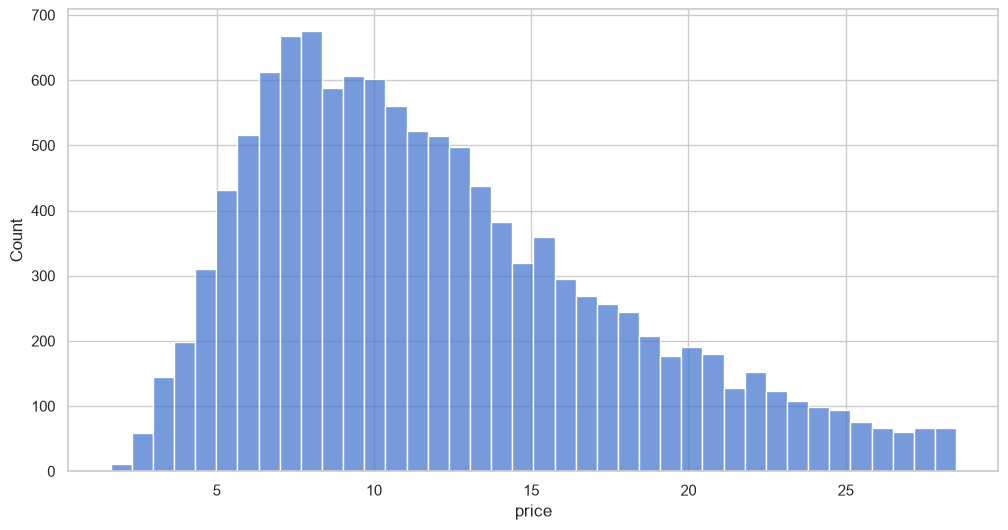

In [45]:
right_price = df.query("price < 28530000")
sns.histplot(data=right_price["price"] / 1_000_000)
df_corrected = df.query("price < 28530000")
df_corrected["price"] = df_corrected["price"] / 1000000

In [46]:
df["price"].quantile(0.95)

np.float64(28530000.0)

## 4. Базовая модель: только площадь
Проверяем, сколько дисперсии может объяснить одна лишь общая площадь квартиры без учета района и ремонта


In [47]:
df_dum = pd.get_dummies(data=df_corrected, drop_first=True).dropna()

smf.ols("price ~ total_area", data=df_dum).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.436
Model:                            OLS   Adj. R-squared:                  0.436
Method:                 Least Squares   F-statistic:                     8382.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:35:39   Log-Likelihood:                -31185.
No. Observations:               10834   AIC:                         6.237e+04
Df Residuals:                   10832   BIC:                         6.239e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.6438      0.115     23.076      0.000       2.419       2.868
total_area     0.1747      0.002     91.553      0.000       0.171       0.178
==============================================================================
Omnibus:                      776.688   Durbin-Watson:                   2.022
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1003.430
Skew:                           0.652   Prob(JB):                    1.28e-218
Kurtosis:                       3.724   Cond. No.                         166.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Выводы по базовой модели:
R^2 = 0.436: площадь в одиночку закрывает почти 44% разброса цен
Коэффициент 0.1747 означает, что один квадратный метр в среднем по рынку стоит около 175 тысяч рублей


## 5. Проверка мультиколлинеарности через VIF
Если загнать в регрессию общую, жилую площадь и кухню одновременно, модель начинает штормить:
Сумма жилой зоны и кухни жестко зажата внутри общей площади, из-за чего VIF улетает в красную зону (18 и 28)


In [22]:
con = sm.add_constant(df_dum.drop(columns=["price"]))
vif_results = vif(con)
vif_results

const                       1.000000
flat_id                     1.001227
rooms                       6.487905
                              ...   
renovation_дизайнерский     1.329807
renovation_евроремонт       1.668522
renovation_косметический    1.761565
Length: 23, dtype: float64

Решение проблемы коллинеарности:
Вместо абсолютных метров переводим жилую зону и кухню в проценты от общей площади квартиры
После этого все VIF возвращаются в норму, а признаки перестают дублировать друг друга


In [48]:
df_vif_corrected = (
    df_corrected.assign(
        living_percent=lambda x: x["living_area"] * 100.0 / x["total_area"],
        kitchen_percent=lambda x: x["kitchen_area"] * 100.0 / x["total_area"],
    )
    .drop(columns=["living_area", "kitchen_area"])
    .dropna()
)

df_vif_corrected_dum = pd.get_dummies(data=df_vif_corrected, drop_first=True)

In [49]:
con2 = sm.add_constant(df_vif_corrected_dum.drop(columns=["price"]))
vif_results = vif(con2)
vif_results

const                      1.00
flat_id                    1.00
rooms                      6.49
                           ... 
renovation_дизайнерский    1.33
renovation_евроремонт      1.67
renovation_косметический   1.76
Length: 23, dtype: float64

## 6. Множественная модель через sm.OLS
Загоняем в матричную спецификацию все ключевые факторы: район, ремонт, этажность, паркинг и удаленность от метро
Сравнение идет относительно базовых категорий: Восточный район и квартиры без ремонта


In [58]:
df_for_model = df_vif_corrected[
    [
        "district",
        "is_first_floor",
        "is_last_floor",
        "total_area",
        "rooms",
        "renovation",
        "minutes_to_metro",
        "has_parking",
        "price",
    ]
]

df_dum = pd.get_dummies(data=df_for_model, drop_first=True)
# сравнение будет происходить с Восточным регионом и без ремонта
X = df_dum["price"]
con = sm.add_constant(df_dum.drop(columns=["price"]))
model = sm.OLS(X, con).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     5989.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:40:48   Log-Likelihood:                -22540.
No. Observations:               10834   AIC:                         4.511e+04
Df Residuals:                   10819   BIC:                         4.522e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -2.0196      0.088    -22.925      0.000      -2.192      -1.847
is_first_floor              -0.7310      0.065    -11.272      0.000      -0.858      -0.604
is_last_floor               -0.4174      0.064     -6.515      0.000      -0.543      -0.292
total_area                   0.1857      0.002     84.716      0.000       0.181       0.190
rooms                        0.3017      0.052      5.857      0.000       0.201       0.403
minutes_to_metro            -0.0949      0.003    -37.795      0.000      -0.100      -0.090
has_parking                  0.3606      0.040      9.111      0.000       0.283       0.438
district_Западный            4.0354      0.064     63.525      0.000       3.911       4.160
district_Пригород           -2.2752      0.086    -26.434      0.000      -2.444      -2.106
district_Северный            2.3346      0.064     36.469      0.000       2.209       2.460
district_Центральный         8.9546      0.071    125.907      0.000       8.815       9.094
district_Южный               0.8604      0.065     13.169      0.000       0.732       0.988
renovation_дизайнерский      4.7253      0.073     64.434      0.000       4.582       4.869
renovation_евроремонт        2.9601      0.056     53.097      0.000       2.851       3.069
renovation_косметический     1.3838      0.050     27.890      0.000       1.287       1.481
==============================================================================
Omnibus:                      441.492   Durbin-Watson:                   1.958
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1243.968
Skew:                           0.157   Prob(JB):                    7.51e-271
Kurtosis:                       4.630   Cond. No.                         438.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Интерпретация весов полной модели:
1. Локация: Центральный район дает огромную надбавку почти в 9 млн рублей относительно Восточного, Западный добавляет 4 млн, а Пригород продается со скидкой в 2.3 млн
2. Ремонт: дизайнерская отделка накидывает в среднем 4.7 млн рублей к аналогичной квартире без ремонта, евроремонт дает плюс 3 млн, а косметика плюс 1.4 млн
3. Этажность: первый этаж дисконтируется сильнее всего (минус 731 тысяча рублей), последний этаж тоже дешевле середины дома, но мягче (минус 417 тысяч)
4. Транспорт: каждая минута пешком до метро снижает ценник квартиры примерно на 95 тысяч рублей
5. Паркинг: наличие машиноместа увеличивает оценку квартиры на 360 тысяч рублей


## 7. Сверка с формульным синтаксисом smf.ols
Обучаем ту же самую спецификацию через формульный интерфейс Patsy с автоматическим кодированием категорий C(...)
Убеждаемся, что коэффициенты обеих моделей сходятся цифра в цифру


In [65]:
smf.ols(
    "price ~ total_area + rooms + minutes_to_metro + has_parking + is_first_floor + is_last_floor + C(district) + C(renovation)",
    data=df_vif_corrected,
).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     5989.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:07:49   Log-Likelihood:                -22540.
No. Observations:               10834   AIC:                         4.511e+04
Df Residuals:                   10819   BIC:                         4.522e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
==================================================================================================
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                         -2.0196      0.088    -22.925      0.000      -2.192      -1.847
C(district)[T.Западный]            4.0354      0.064     63.525      0.000       3.911       4.160
C(district)[T.Пригород]           -2.2752      0.086    -26.434      0.000      -2.444      -2.106
C(district)[T.Северный]            2.3346      0.064     36.469      0.000       2.209       2.460
C(district)[T.Центральный]         8.9546      0.071    125.907      0.000       8.815       9.094
C(district)[T.Южный]               0.8604      0.065     13.169      0.000       0.732       0.988
C(renovation)[T.дизайнерский]      4.7253      0.073     64.434      0.000       4.582       4.869
C(renovation)[T.евроремонт]        2.9601      0.056     53.097      0.000       2.851       3.069
C(renovation)[T.косметический]     1.3838      0.050     27.890      0.000       1.287       1.481
total_area                         0.1857      0.002     84.716      0.000       0.181       0.190
rooms                              0.3017      0.052      5.857      0.000       0.201       0.403
minutes_to_metro                  -0.0949      0.003    -37.795      0.000      -0.100      -0.090
has_parking                        0.3606      0.040      9.111      0.000       0.283       0.438
is_first_floor                    -0.7310      0.065    -11.272      0.000      -0.858      -0.604
is_last_floor                     -0.4174      0.064     -6.515      0.000      -0.543      -0.292
==============================================================================
Omnibus:                      441.492   Durbin-Watson:                   1.958
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1243.968
Skew:                           0.157   Prob(JB):                    7.51e-271
Kurtosis:                       4.630   Cond. No.                         438.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 8. Итоги и выбор модели для сервиса оценки


Финальный вердикт:
Для продакшена однозначно берем множественную модель:
1. Объясняющая сила R^2 adj выросла в два раза: с 0.436 до 0.886. Модель закрывает почти 89% ценообразования вторички
2. Информационные критерии подтверждают превосходство: AIC упал с 62 370 до 45 110 (разница более 17 000 пунктов)
3. Все коэффициенты логичны по знакам, устойчивы и статистически значимы на уровне p < 0.001
